In [15]:
import pandas as pd
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay, confusion_matrix
import matplotlib.pyplot as plt


In [3]:
#Load in the dataset
penguin_size = pd.read_csv('/content/penguins_size.csv')

#drop columns with NaN
penguin_size_cleaned = penguin_size.dropna().copy()
penguin_size_cleaned.head()

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,MALE


**1. Preparing Features and Target Variables**

We will separate features (X) and target variable (y) from the dataset.

All features except 'island' will be used, as it is the giveaway as certain species live on specific island.

In [4]:
penguin_size_cleaned['sex'] = LabelEncoder().fit_transform(penguin_size_cleaned['sex'])
X = penguin_size_cleaned[['culmen_length_mm', 'culmen_depth_mm', 'flipper_length_mm', 'body_mass_g','sex']]
y = penguin_size_cleaned['species']


**2. Split Dataset into Training and Testing**

* Split the data into 70% training and 30% testing sets. The random_state parameter ensures reproducibility of the data.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

print(f"Total number of data points:", len(X))
print(f"Training data points:", len(X_train))
print(f"Testing testing points:", len(X_test))

Total number of data points: 334
Training data points: 233
Testing testing points: 101


In [31]:
X_train

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
292,48.2,15.6,221.0,5100.0,2
302,47.4,14.6,212.0,4725.0,1
62,37.6,17.0,185.0,3600.0,1
181,52.8,20.0,205.0,4550.0,2
15,36.6,17.8,185.0,3700.0,1
...,...,...,...,...,...
194,50.9,19.1,196.0,3550.0,2
77,37.2,19.4,184.0,3900.0,2
112,39.7,17.7,193.0,3200.0,1
277,45.5,15.0,220.0,5000.0,2


In [32]:
X_test

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
30,39.5,16.7,178.0,3250.0,1
317,46.9,14.6,222.0,4875.0,1
79,42.1,19.1,195.0,4000.0,2
201,49.8,17.3,198.0,3675.0,1
63,41.1,18.2,192.0,4050.0,2
...,...,...,...,...,...
7,39.2,19.6,195.0,4675.0,2
215,55.8,19.8,207.0,4000.0,2
99,43.2,18.5,192.0,4100.0,2
35,39.2,21.1,196.0,4150.0,2


**3. Train and Predict Decision Tree Using Gini Index**


In [26]:
tree_gini = DecisionTreeClassifier(criterion="gini", random_state=42, max_depth=3, min_samples_leaf=5)
tree_gini.fit(X_train, y_train)

y_pred_gini = tree_gini.predict(X_test)


In [29]:
#tree_gini with no max_depth
tree_gini_nomaxdepth = DecisionTreeClassifier(criterion="gini", random_state=42, min_samples_leaf=5)
tree_gini_nomaxdepth.fit(X_train, y_train)

y_pred_gini_nomaxdepth = tree_gini_nomaxdepth.predict(X_test)


**4. Train and Predict Decision Using Entropy**



In [7]:
tree_entropy = DecisionTreeClassifier(criterion="entropy", random_state=42, max_depth=3, min_samples_leaf=5)
tree_entropy.fit(X_train, y_train)

y_pred_entropy=tree_entropy.predict(X_test)

**5. Visualize Decision Trees**

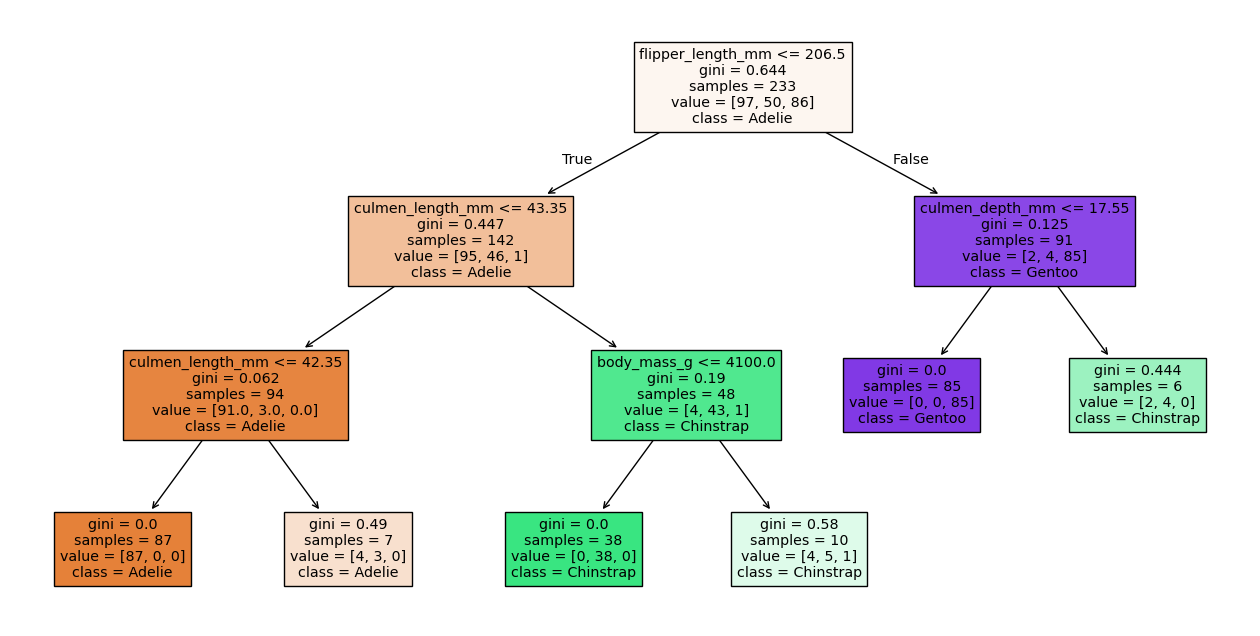

In [23]:
#Split tree using Gini
plt.figure(figsize=(16,8))
plot_tree(
    tree_gini,
    feature_names=list(X.columns),
    class_names=list(tree_gini.classes_),
    filled=True
)
plt.show()

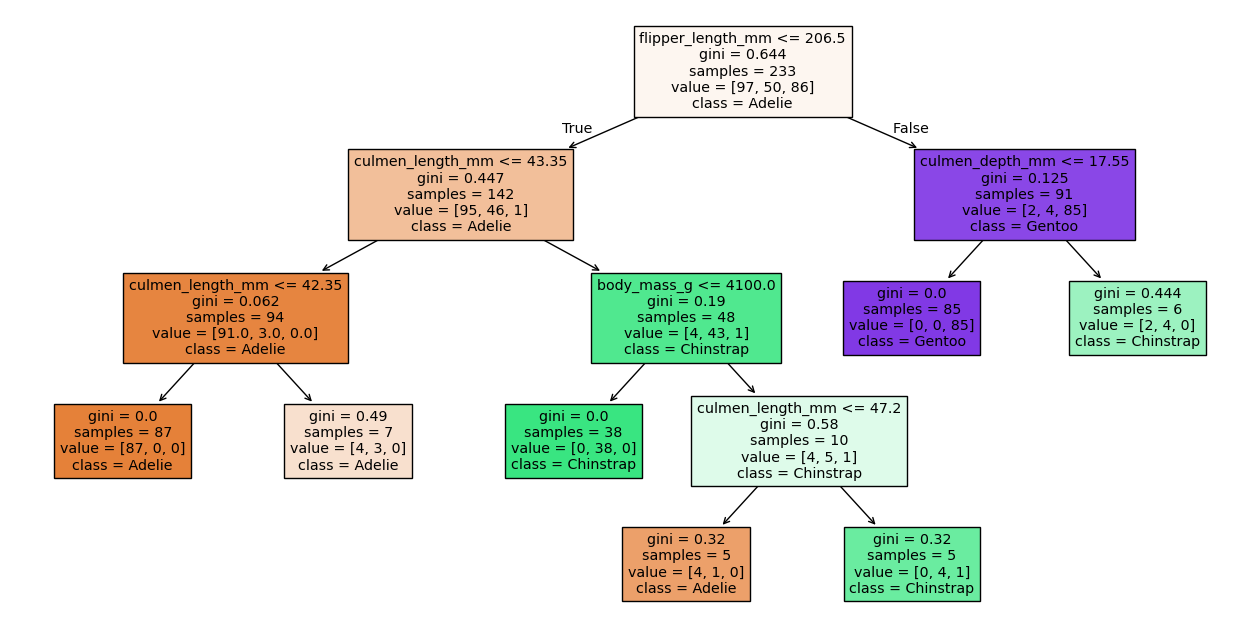

In [28]:
#Split tree using Gini with no max_depth
plt.figure(figsize=(16,8))
plot_tree(
    tree_gini_nomaxdepth,
    feature_names=list(X.columns),
    class_names=list(tree_gini_nomaxdepth.classes_),
    filled=True
)
plt.show()

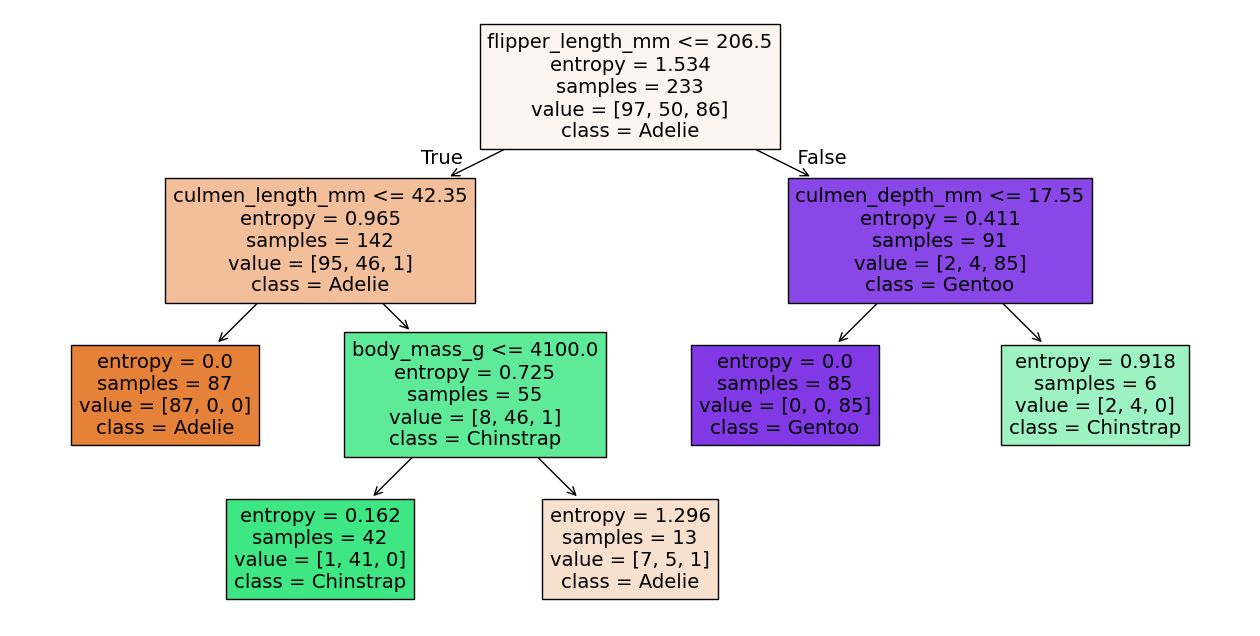

In [24]:
#Split tree using Entropy
plt.figure(figsize=(16,8))
plot_tree(
    tree_entropy,
    feature_names=list(X.columns),
    class_names=list(tree_entropy.classes_),
    filled=True
)
plt.show()

**6. Evaluate Decision Trees**

In [30]:
#Using Gini
accuracy_gini = accuracy_score(y_true=y_test, y_pred=y_pred_gini)
print(f"Accuracy of Predicting Species using Gini: {accuracy_gini}")

#Using Entropy
accuracy_entropy = accuracy_score(y_true=y_test, y_pred=y_pred_entropy)
print(f"Accuracy of Predicting Species using Entropy: {accuracy_entropy}")

#Using Gini with no max depth
accuracy_gini_nomaxdepth = accuracy_score(y_true=y_test, y_pred=y_pred_gini_nomaxdepth)
print(f"Accuracy of Predicting Species using Gini with No Max_depth: {accuracy_gini_nomaxdepth}")

Accuracy of Predicting Species using Gini: 0.9801980198019802
Accuracy of Predicting Species using Entropy: 0.9504950495049505
Accuracy of Predicting Species using Gini with No Max_depth: 0.9801980198019802


Text(0.5, 1.0, 'Confusion Matrix for Decision Tree using Entropy')

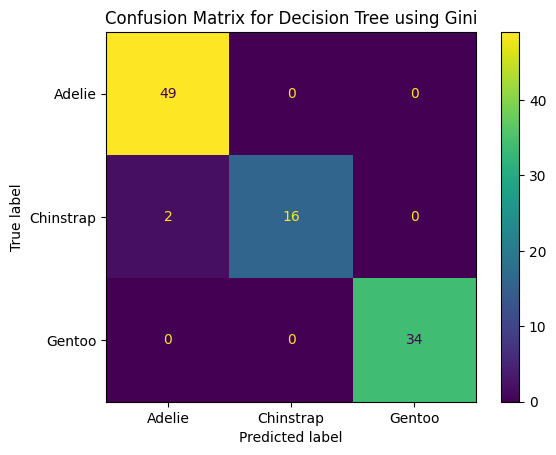

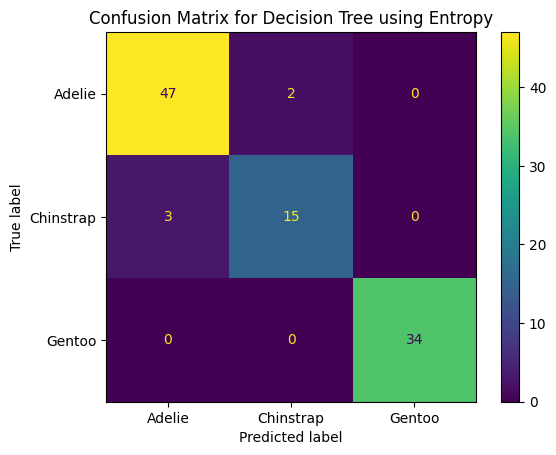

In [10]:
matrix_gini = ConfusionMatrixDisplay.from_predictions(y_test, y_pred_gini)
matrix_gini.ax_.set_title("Confusion Matrix for Decision Tree using Gini")

matrix_entropy = ConfusionMatrixDisplay.from_predictions(y_test, y_pred_entropy)
matrix_entropy.ax_.set_title("Confusion Matrix for Decision Tree using Entropy")
